# Lab 5: validation across all seven Ghia Reynolds numbers

This standalone CPU lab follows the original Week 1/1.2 and Week 4 CFD lessons.
It widens the **reference and experimental parameter range** to $Re=100,400,1000,3200,5000,7500,10000$.
Ghia's Tables I and II give 17 samples on each centreline, not a full flow field.
The square cavity has width $L$, lid speed $U$, $Re=UL/\nu$, and a discontinuous
moving lid at its upper corners. A smooth-lid or deep cavity is a different problem.

[Benchmark source and anomaly policy](../../references/ghia/README.md) ·
[Experiment, results and limitations](../../results/cavity_ghia_allre/README.md) ·
[Setup](../../START_HERE.md).

Three suspicious **printed** entries remain in the raw tables. We show both the
unfiltered score and a predeclared screened sensitivity score; we never silently
replace them with a plausible number. A train/test split by individual points
would leak the same Reynolds number into both sets.

For $N$ retained samples, report
$$E_u=\frac{\sqrt{\sum_i(\hat u_i-u_i)^2}}{\sqrt{\sum_i u_i^2}},\qquad
e_{\mathrm{RMS},u}/U=\sqrt{\frac1N\sum_i[(\hat u_i-u_i)/U]^2}.$$
Use the analogous definitions for $v$. The norm denominator is shared over the
profile, so a reference zero crossing causes no pointwise division by zero.
The code stores velocities already divided by $U$.

In [1]:
from pathlib import Path
import sys, subprocess
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1','https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file():
        raise RuntimeError('This checkout predates the cavity extension. Use an updated FlowMLLab checkout after saving your student work; do not overwrite your edited notebook.')
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from flowmllab import ghia, cavity_course as course

Re = 100: original samples; markers are not a reconstructed 2D field
Re = 400: original samples; markers are not a reconstructed 2D field
Re = 1000: original samples; markers are not a reconstructed 2D field
Re = 3200: original samples; markers are not a reconstructed 2D field
Re = 5000: original samples; markers are not a reconstructed 2D field
Re = 7500: original samples; markers are not a reconstructed 2D field
Re = 10000: original samples; markers are not a reconstructed 2D field


,Re,reference_samples,flagged_samples,profile_study_role,retained_field,scope
0,100,34,0,train,data/cavity_data.npz,retained evidence; inspect its own mesh/steady...
1,400,34,1,validation,results/week01_2_formulations/streamfunction-v...,retained evidence; inspect its own mesh/steady...
2,1000,34,0,train,results/week01_2_formulations/streamfunction-v...,retained evidence; inspect its own mesh/steady...
3,3200,34,1,test,None,no retained full field; benchmark table only
4,5000,34,0,train,None,no retained full field; benchmark table only
5,7500,34,0,test,None,no retained full field; benchmark table only
6,10000,34,1,train,None,no retained full field; benchmark table only


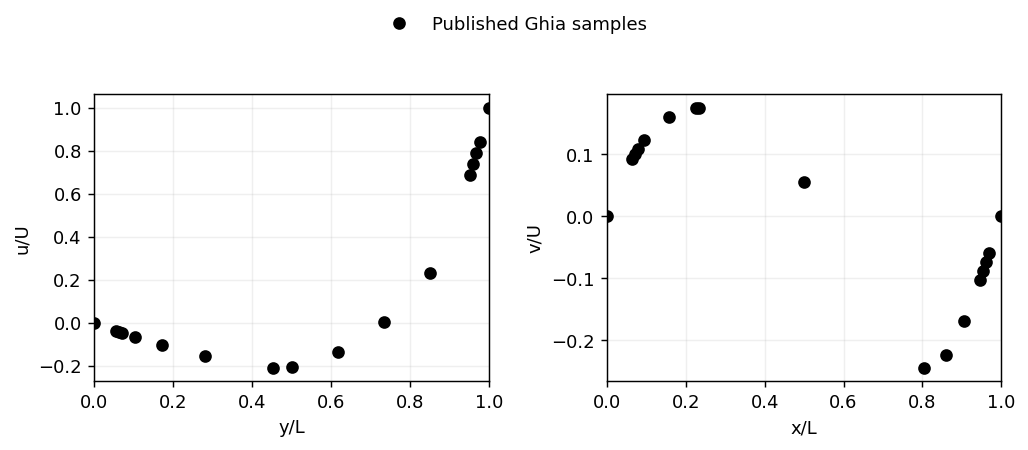

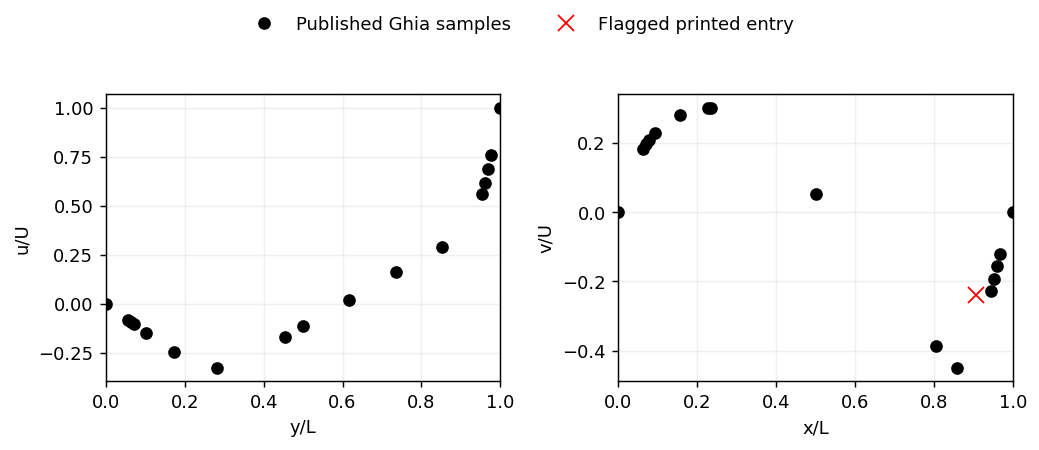

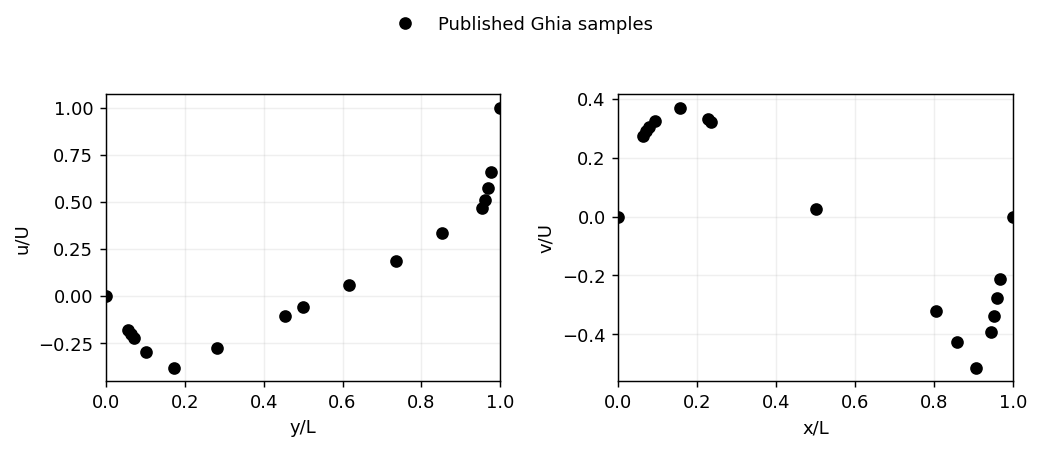

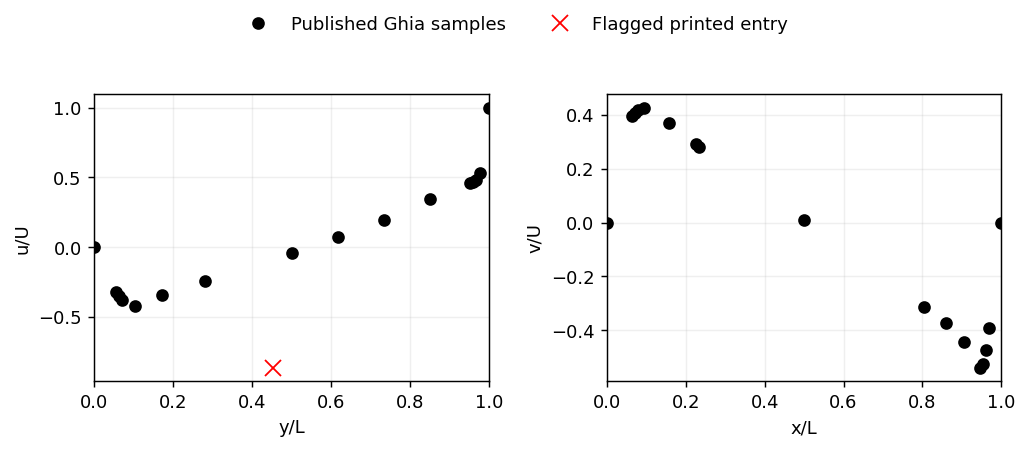

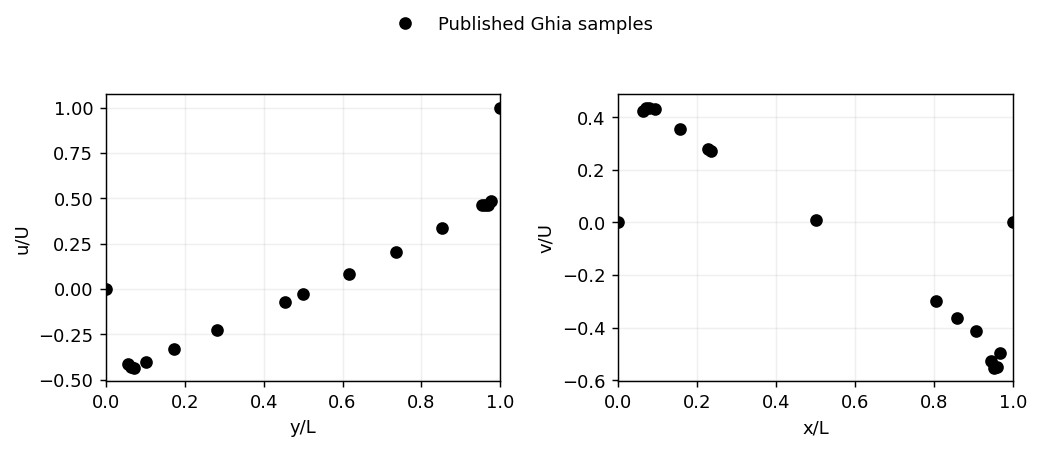

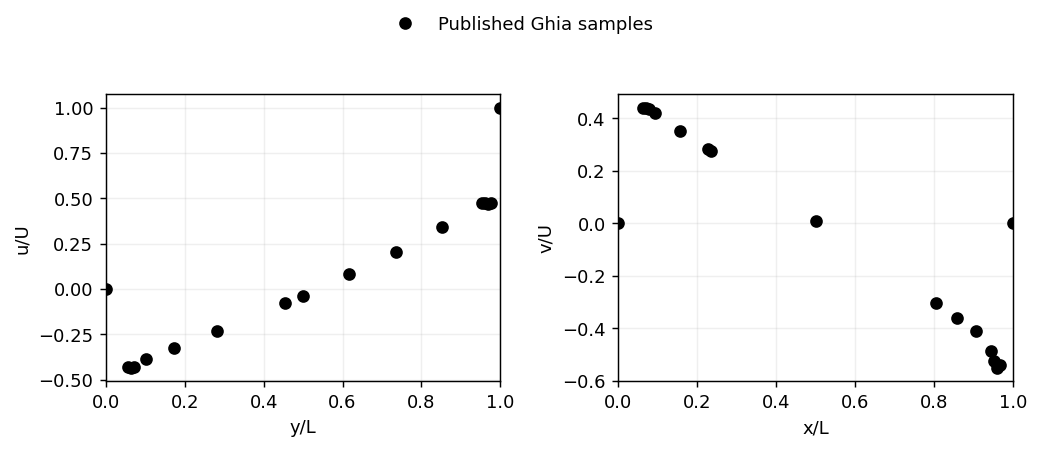

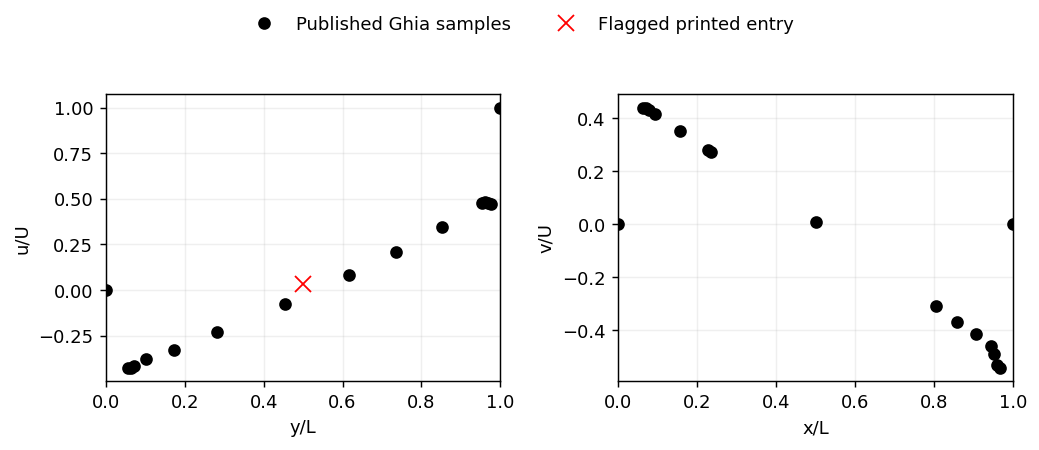

In [2]:
coverage = pd.DataFrame(course.coverage(ROOT))
display(coverage)
for re in ghia.REYNOLDS:
    print(f'Re = {re}: original samples; markers are not a reconstructed 2D field')
    course.plot_reference(re)
    plt.show()

### CFD admission before neural training

The coverage table explicitly distinguishes a tabulated reference from a retained
full field. Re=3200, 5000, 7500 and 10000 do **not** acquire validated CFD fields
because their names appear in a dropdown. A small update at a small time step
does not prove a steady solution. At high Re, a coarse discretization and the lid
corner singularity can dominate the discrepancy.

For each new case save the grid, time step, convection scheme, residual history,
physical time, wall treatment and signed centreline differences. Compare at least
three grids and halve the time step; inspect steady residuals, vortex locations,
mass balance and both velocity profiles. If the solution remains time dependent,
report this and do not average it into a supposedly steady Ghia validation.

The experimental pressure-velocity wrapper accepts all seven Re values. The
existing qualified Re=100 implementation and original low-Re field datasets
retain their original scope. Ghia velocity agreement does not validate pressure.

In [3]:
# Optional expensive study: choose ONE case, inspect it, then refine.
# This switch is deliberately off for a quick classroom Run All.
RUN_NEW_CFD = False
RE_TO_SOLVE = 3200
CELLS = 128
if RUN_NEW_CFD:
    from flowmllab.streamfunction_experiments import run_streamfunction
    field = run_streamfunction(reynolds=RE_TO_SOLVE, cells=CELLS,
                              dt=0.0005, max_steps=400000, progress=False)
    display({k:field[k] for k in ['status','steps','steady_vorticity_linf',
                                'continuity_linf','ghia_u_relative_l2','ghia_v_relative_l2']})
    display(course.compare_field(RE_TO_SOLVE,field['x'],field['y'],field['u'],field['v']))
    # A passed steady gate is necessary, but mesh/time-step comparisons are still required.
else:
    print('No new CFD solve requested. High-Re full-field validation remains unqualified.')

No new CFD solve requested. High-Re full-field validation remains unqualified.


### Specific student tasks: validation across Reynolds number

1. **Reference sensitivity.** For each of the three flagged entries, report the
   coordinate and printed value. Compute both scores using the same prediction.
   Explain which conclusion changes. Do not choose a mask after inspecting your error.
2. **Mesh study.** Start with Re=400 or 1000, using the retained 32/64/128-cell
   results. Make a table with grid size, time step, steady residual, $E_u$, $E_v$,
   and vortex centre. Decide what is and is not converged. Then design the same
   table for one of 3200/5000/7500/10000; label missing runs as missing.
3. **Numerical method.** Keep Re, grid, boundary conditions and stopping criteria
   fixed while comparing SIMPLE, PISO and PIMPLE. Compare pressure solves and
   elapsed time at the same achieved accuracy. SIMPLE iteration count is not
   physical time; PISO/PIMPLE time steps require a separate temporal-accuracy check.
4. **Data acceptance.** Write a one-paragraph acceptance/rejection decision for
   each of the seven Re values. A benchmark table alone is not a field-training
   case. Include signs and near-wall behaviour in your plots, not only an error norm.